### Importing Relevent Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')  # Hide warning messages

sns.set()  # All plot will cover on seaborn style

### Load Dataset

In [2]:
car_raw = pd.read_csv("Data/Car_Raw_Data.csv")

car_raw.head()

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991,320
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999,Sprinter 212
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003,S 500
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007,Q7
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011,Rav 4


* Brand - Car brand. 
* Price - Price of the car ($), and our `target` column.
* Body - Car body type.
* Mileage - How much the car has driven. From observing the dataset, the mileage values appear to be represented in thousand kilometers. As it is a second hand car price prediction project,It is more likely the car has driven most the price will be less.
* EngineV - Volume of the car engine. Sports cars usually have larger engines and higher prices, while economy cars have comparatively smaller engines and lower prices.
* Engine Type - Type of fuel used by the car engine.
* Registration - Whether the car has registration papers or not.
* Year - The year when the car was first bought by the first owner. Older cars are usually cheaper.
* Model - Model of the car.

## Preprocessing the Raw Data

In [3]:
#car_raw.describe()
car_raw.describe(include='all')

# use include = all for getting categorical column also.

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year,Model
count,4345,4173.000000,4345,4345.000000,4195.000000,4345,4345,4345.000000,4345
unique,7,NaN,6,NaN,NaN,4,2,NaN,312
top,Volkswagen,NaN,sedan,NaN,NaN,Diesel,yes,NaN,E-Class
freq,936,NaN,1649,NaN,NaN,2019,3947,NaN,199
mean,NaN,19418.746935,NaN,161.237284,2.790734,NaN,NaN,2006.550058,NaN
std,NaN,25584.242620,NaN,105.705797,5.066437,NaN,NaN,6.719097,NaN
min,NaN,600.000000,NaN,0.000000,0.600000,NaN,NaN,1969.000000,NaN
25%,NaN,6999.000000,NaN,86.000000,1.800000,NaN,NaN,2003.000000,NaN
50%,NaN,11500.000000,NaN,155.000000,2.200000,NaN,NaN,2008.000000,NaN
75%,NaN,21700.000000,NaN,230.000000,3.000000,NaN,NaN,2012.000000,NaN


As the `Model` column is contain `312` unique model of cars, and after converting it on dummy variable the dimention of our data will be very high, it will increase `312` more columns into out data. 

Also there is another asumtion i have made that it is second hand or old car price dataset, so when the car get old we really don't care about which model it is, but the car `Brand` will give some impact.

That is why for now i will drop the `Model` column from the dataset.

In [4]:
# dropping the model column
car_raw = car_raw.drop("Model", axis=1)

In [5]:
car_raw.describe(include='all')

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
count,4345,4173.000000,4345,4345.000000,4195.000000,4345,4345,4345.000000
unique,7,NaN,6,NaN,NaN,4,2,NaN
top,Volkswagen,NaN,sedan,NaN,NaN,Diesel,yes,NaN
freq,936,NaN,1649,NaN,NaN,2019,3947,NaN
mean,NaN,19418.746935,NaN,161.237284,2.790734,NaN,NaN,2006.550058
std,NaN,25584.242620,NaN,105.705797,5.066437,NaN,NaN,6.719097
min,NaN,600.000000,NaN,0.000000,0.600000,NaN,NaN,1969.000000
25%,NaN,6999.000000,NaN,86.000000,1.800000,NaN,NaN,2003.000000
50%,NaN,11500.000000,NaN,155.000000,2.200000,NaN,NaN,2008.000000
75%,NaN,21700.000000,NaN,230.000000,3.000000,NaN,NaN,2012.000000


## Checking Missing values

In [6]:
car_raw.isnull().sum()

Brand             0
Price           172
Body              0
Mileage           0
EngineV         150
Engine Type       0
Registration      0
Year              0
dtype: int64

`Price` and `EngineV` is only column with missng values. but few of them are missing.

`The Rule of Thumb` says if we are dropiing or removing `5%` or less than that data from the original data. we are safely remove that.

In our this case `172/4344` `=` `0.0395`, we are droping like `3%` of total data, 

In [7]:
# Dropping missing values
car_raw = car_raw.dropna(axis=0)

# dropna(axis=0) -> Remove rows that contain missing values.

In [8]:
car_raw.isnull().sum()

Brand           0
Price           0
Body            0
Mileage         0
EngineV         0
Engine Type     0
Registration    0
Year            0
dtype: int64

### Exploratory Data Analysis (EDA)

Text(0.5, 1.0, 'Car Price Distribution')

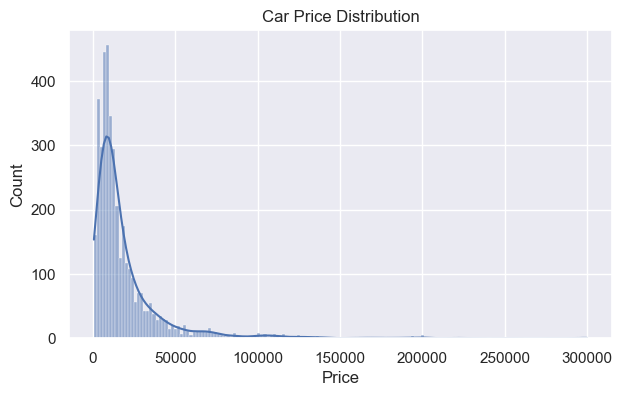

In [9]:
plt.figure(figsize=(7,4))

sns.histplot(car_raw['Price'], kde=True)
plt.title('Car Price Distribution')

If we check the price range, the values are lies in very strage order. also there are some outliar.

### Dealing with outliar.

The one way is to do that is getting 99% of total data and removing 1% of data.

for that I will use pandas `.quantile()` methode

In [10]:
q = car_raw['Price'].quantile(q = 0.99) # It returns a single value
q

np.float64(129812.51999999981)

q = 0.99 → 99% data below this value

In [11]:
# Updating the data
car_1 = car_raw[car_raw['Price']<q]

car_1.describe()    #Checking the data

,Price,Mileage,EngineV,Year
count,3984.000000,3984.000000,3984.000000,3984.000000
mean,17837.117460,165.116466,2.743770,2006.292922
std,18976.268315,102.766126,4.956057,6.672745
min,600.000000,0.000000,0.600000,1969.000000
25%,6980.000000,93.000000,1.800000,2002.750000
50%,11400.000000,160.000000,2.200000,2007.000000
75%,21000.000000,230.000000,3.000000,2011.000000
max,129222.000000,980.000000,99.990000,2016.000000


### Removing Outliers

After calculating the 99th percentile value `q`, we remove all rows where the car price is greater than `q`.

This keeps only the **lowest 99% of the data** and removes the **top 1% extreme values**, which are considered outliers.

- Now if we compare from above describe then we can see the `Price` max value has been relaxed, but it also very far from its mean, but it is acceptable.

Text(0.5, 1.0, 'With Outliars')

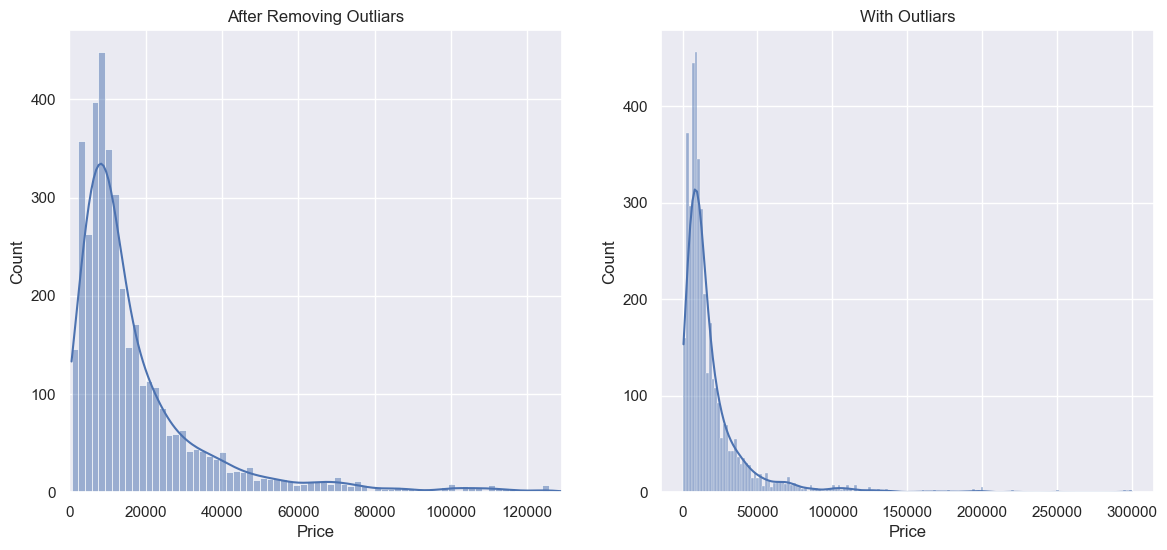

In [12]:
plt.figure(figsize=(14,6))
# plotting distribution graph with seaborn
# plotting the Target Column prices

plt.subplot(1,2,1)
sns.histplot(car_1['Price'], kde=True)
plt.title('After Removing Outliars')
plt.xlim(0,129222)


plt.subplot(1,2,2)
sns.histplot(car_raw['Price'], kde=True)
plt.title('With Outliars')

Now the outliars are far away, Now we can see the Price is more generalized way.

### This similar issue we also have with others columns like `Mileage`, `EngineV` and `Year`

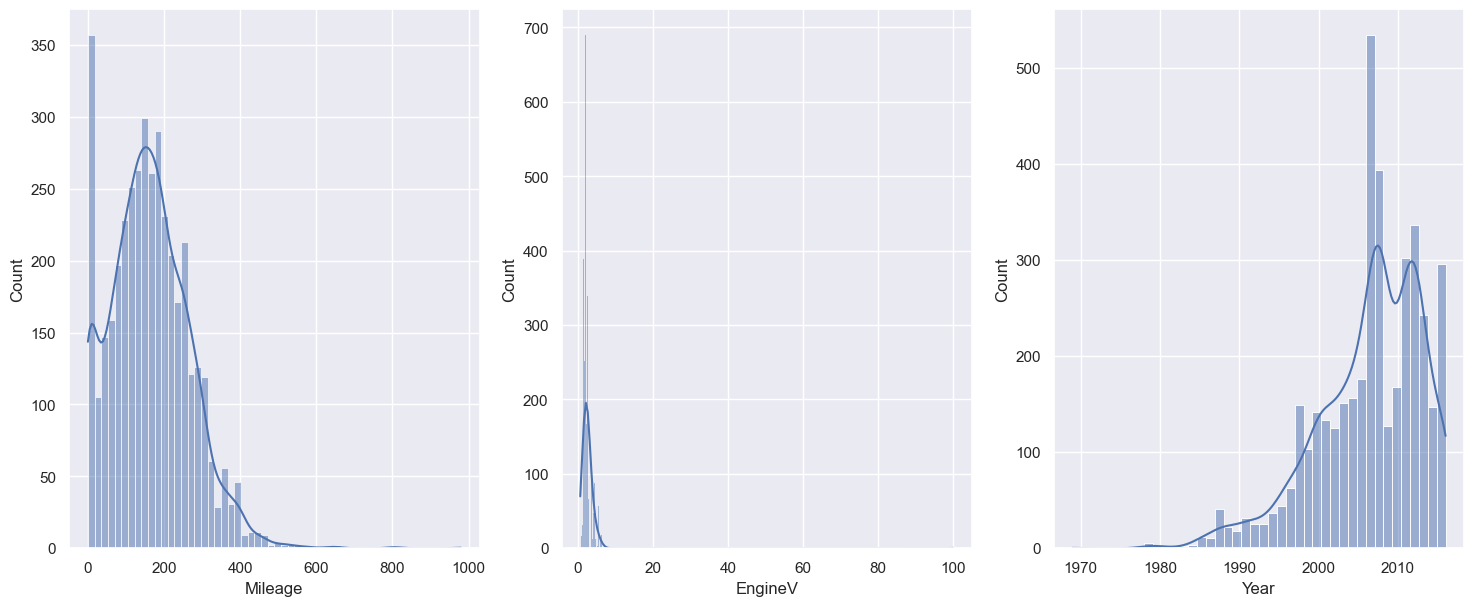

In [13]:
# potting others numerical columns
plt.figure(figsize=(18,7))

plt.subplot(1,3,1)     #subplot(rows, columns, position)
sns.histplot(car_raw['Mileage'], kde=True);

plt.subplot(1,3,2)
sns.histplot(car_raw['EngineV'], kde=True)

plt.subplot(1,3,3)
sns.histplot(car_raw['Year'], kde=True);

The same things is also here. I will perform the same processing here also, kepping only 99% data

In [14]:
## Mileage Column.
q = car_1['Mileage'].quantile(0.99)  # it return a single value
car_2  = car_1[car_1['Mileage']<q]

Text(0.5, 1.0, 'With Outliars')

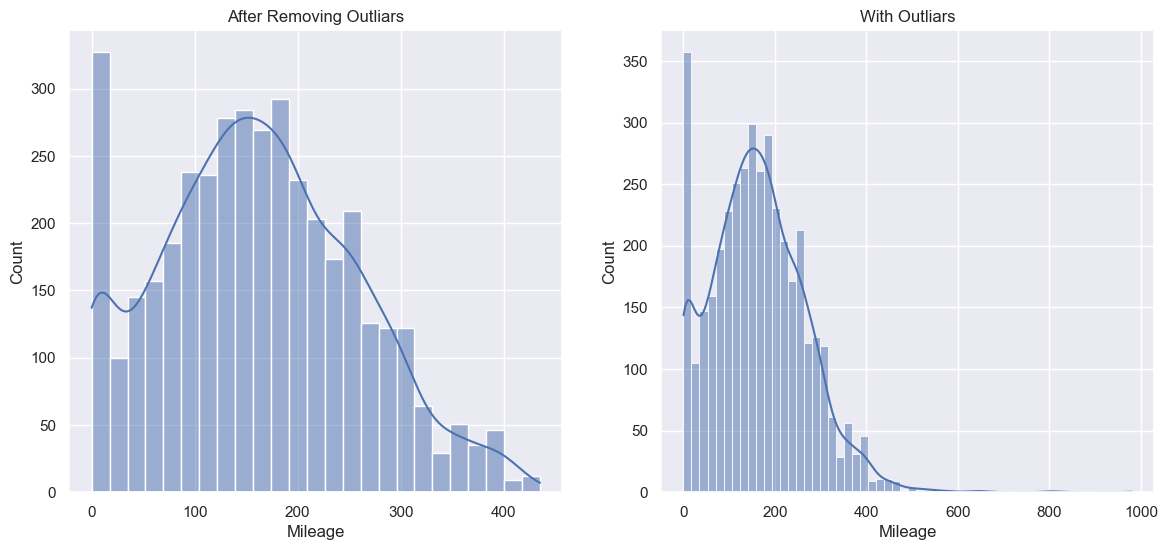

In [15]:
plt.figure(figsize=(14,6))
# plotting distribution graph with seaborn
# plotting the Target Column prices

plt.subplot(1,2,1)
sns.histplot(car_2['Mileage'], kde=True)
plt.title('After Removing Outliars')


plt.subplot(1,2,2)
sns.histplot(car_raw['Mileage'], kde=True)
plt.title('With Outliars')

Now the is much look like normally distributed.

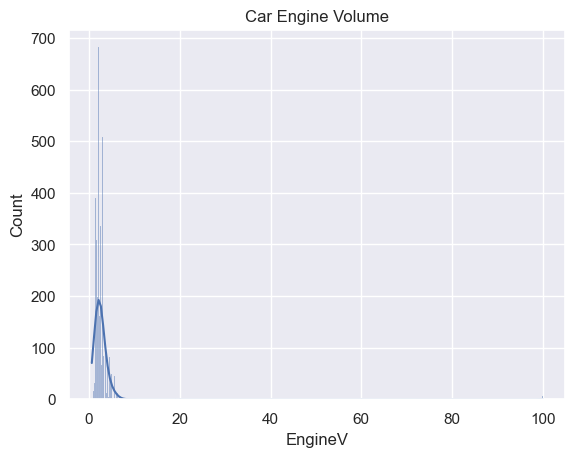

In [16]:
# plotting the EngineV column
sns.histplot(car_2['EngineV'], kde=True);
plt.title('Car Engine Volume');

The `EngineV` column contains some unrealistic values. From the dataset description, I observed the maximum engine volume is `99.9`, which is not realistic for cars.

After researching, I found that most car engine volumes usually fall within the range of `0.6L to 6.5L`.

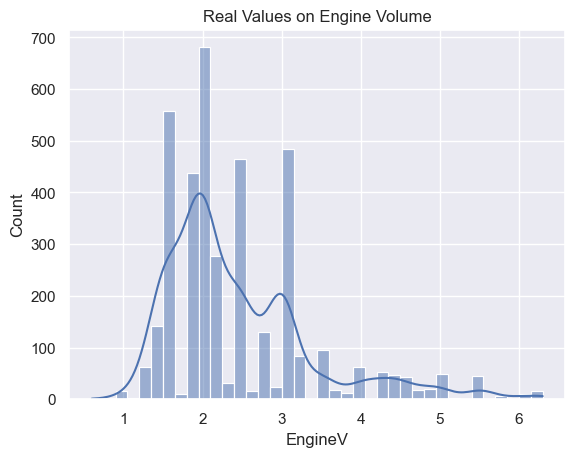

In [17]:
# as here I know the max engine volume can be is 6.5


car_3  = car_2[car_2['EngineV']<6.5]    

# plotting the values again
sns.histplot(car_3['EngineV'], kde=True);
plt.title('Real Values on Engine Volume');

car_2[ ... ]

This part tells pandas:

"Select rows from car_2 where the condition is True."

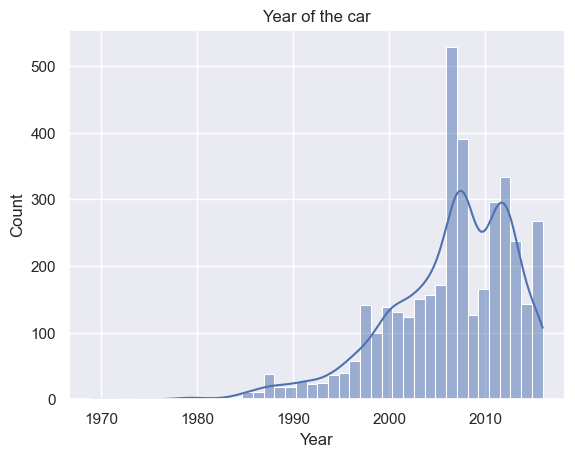

In [18]:
# plotting the Year column

sns.histplot(car_3['Year'], kde=True);
plt.title('Year of the car');

Now here the problem is kind of opposite. Most cars are newer models from after 2000, but there are also a few cars older than 1990.

As I noticed, the `Year` column is treated like a normal numerical column rather than a datetime feature.

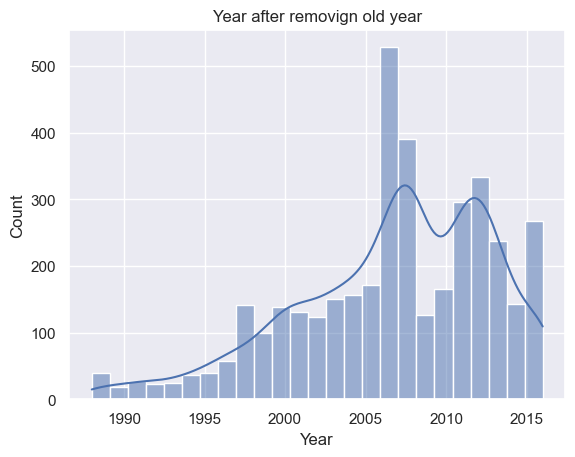

In [19]:
q = car_3['Year'].quantile(0.01);
car_4 = car_3[car_3['Year']>q] # removing the 1th percentile data

# potting again
sns.histplot(car_4['Year'], kde=True);
plt.title('Year after removign old year');

In [20]:
car_4

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011
...,...,...,...,...,...,...,...,...
4338,Volkswagen,11500.0,van,163,2.5,Diesel,yes,2008
4339,Toyota,17900.0,sedan,35,1.6,Petrol,yes,2014
4340,Mercedes-Benz,125000.0,sedan,9,3.0,Diesel,yes,2014
4341,BMW,6500.0,sedan,1,3.5,Petrol,yes,1999


- Now from here I can see that the index is little messed up. It is because we have remove some row from the data but the index is showing fron the raw data, that is why the last index value is not matching with total no of rows.

In [21]:
# reset the indexes
car_clean = car_4.reset_index(drop=True)

In [22]:
car_clean

,Brand,Price,Body,Mileage,EngineV,Engine Type,Registration,Year
0,BMW,4200.0,sedan,277,2.0,Petrol,yes,1991
1,Mercedes-Benz,7900.0,van,427,2.9,Diesel,yes,1999
2,Mercedes-Benz,13300.0,sedan,358,5.0,Gas,yes,2003
3,Audi,23000.0,crossover,240,4.2,Petrol,yes,2007
4,Toyota,18300.0,crossover,120,2.0,Petrol,yes,2011
...,...,...,...,...,...,...,...,...
3862,Volkswagen,11500.0,van,163,2.5,Diesel,yes,2008
3863,Toyota,17900.0,sedan,35,1.6,Petrol,yes,2014
3864,Mercedes-Benz,125000.0,sedan,9,3.0,Diesel,yes,2014
3865,BMW,6500.0,sedan,1,3.5,Petrol,yes,1999


### Now the row are matching with.

In [23]:
car_raw.shape[0] -  car_clean.shape[0]

158

I have removed total 158 rows from the raw data.

But the original number is `158 + 172 = 330`. because I have remove null value in the begining.

In [26]:
# saving the data for next modeule

car_clean.to_csv('Data/Car_cleaned.csv', index=False)